# Trajectory: two-stage deep ensembles (FiLM and MLP), out of distribution

As `deep_ensembles_pipeline.ipynb`, but each network first learns the means with MSE only, then is frozen while only its variance output learns (Gaussian NLL). The FiLM one is our out-of-distribution submission.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import shutil

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import pallas_pipeline as pp
import pallas_score

project = pp.connect(pp.PROJECT)
fs = project.get_feature_store()
case = pp.CASES["trajectory"]
PARAMS = {"two_stage": True, "use_physics": True, "physics": ["dE_gain", "n_e"], "val_fraction": 1 / 3, "device": "cuda:1"}
split, seed, register = "ood_density", 12, False
names = {f: f"m_trajectory_{f}_two_stage_ood" for f in ["film_deep_ensemble", "mlp_deep_ensemble"]}

/home/mlenivenko/miniconda3/envs/torch/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026-10-15 16:34:22,111 INFO: Initializing external client


2026-10-15 16:34:22,112 INFO: Base URL: https://aissai26.hops.live:443


2026-10-15 16:34:23,272 INFO: Python Engine initialized.



Logged in to project, explore it here https://aissai26.hops.live:443/p/2170


## Feature view and split

Raw inputs (the models standardise them and compute the physics features). `ood_density`: train on the configs below the pressure cut, score on the public ones above it.

In [2]:
fv = pp.get_feature_view(fs, "m_trajectory_raw_fv", 1) or pp.create_feature_view(
    fs, case, "m_trajectory_raw_fv", 1, {c: "none" for c in case.inputs}, description="trajectory, raw inputs")
td_version = pp.prepare_statistics(fv)
rows = pp.read_rows(fv, case)
inside = set(pp.pack_reference()["sections"]["ood_split"]["train"])
train_configs = sorted(int(c) for c in rows.config.unique() if c in inside)
holdout_configs = sorted(int(c) for c in rows.config.unique() if c not in inside)
train = rows[rows.config.isin(train_configs)].reset_index(drop=True)
holdout = rows[rows.config.isin(holdout_configs)].reset_index(drop=True)
X_train, X_holdout = pp.transform(fv, train, case), pp.transform(fv, holdout, case)
key = pp.answer_key(case, holdout)
true = np.column_stack([pallas_score.physical_to_normalised(t, holdout[t]) for t in case.targets])
inside = (holdout.z_mm <= holdout.L_inj + pallas_score.PLASMA_END_OFFSET_MM).to_numpy()
print(f"{len(train_configs)} train configs, {len(holdout_configs)} holdout configs")

Finished: Reading data from Hopsworks, using Hopsworks Feature Query Service (51.47s) 
2277 train configs, 578 holdout configs


## Train and score

In-plasma R² on the holdout, and how often the error is below 2 × the ensemble's spread (95% if calibrated).

In [3]:
results = {}
for f in names:
    module = pp.load_model_file(f"models/{f}.py")
    params = {**module.PARAMS, **PARAMS, "columns": list(X_train.columns)}
    model = pp.SurrogateModel(module.build_model(**params), case.targets, "scorer").fit(X_train, train)
    pred = pp.predictions(case, model, X_holdout, holdout)
    mean, spread = model.estimator.predict_with_spread(np.asarray(X_holdout, float))
    results[f] = {"model": model, "params": params, "pred": pred, "scores": pallas_score.score_submission(pred, key),
                  "cover": (np.abs(true - mean) < 2 * spread)[inside].mean(0)}

display(pd.DataFrame({f: r["scores"] for f, r in results.items()}).loc[case.targets + ["mean"]].round(4))
display(pd.DataFrame({f: r["cover"] for f, r in results.items()}, index=case.targets).round(3))

1518 train / 759 validation configurations, 5 + 3 inputs, on cuda:1


member 0: epoch 57


member 1: epoch 143


member 2: epoch 127


member 3: epoch 99


...

member 2: epoch 182


member 3: epoch 152


member 4: epoch 184


,film_deep_ensemble,mlp_deep_ensemble
E_MeV,0.9909,0.9896
q_pC,0.9983,0.9975
dE_pct,0.9719,0.9698
emit_um,0.9638,0.9621
div_mrad,0.9757,0.9783
sigz_um,0.8897,0.8719
mean,0.9651,0.9615


,film_deep_ensemble,mlp_deep_ensemble
E_MeV,0.983,0.969
q_pC,0.997,0.995
dE_pct,0.927,0.914
emit_um,0.974,0.969
div_mrad,0.975,0.968
sigz_um,0.913,0.892


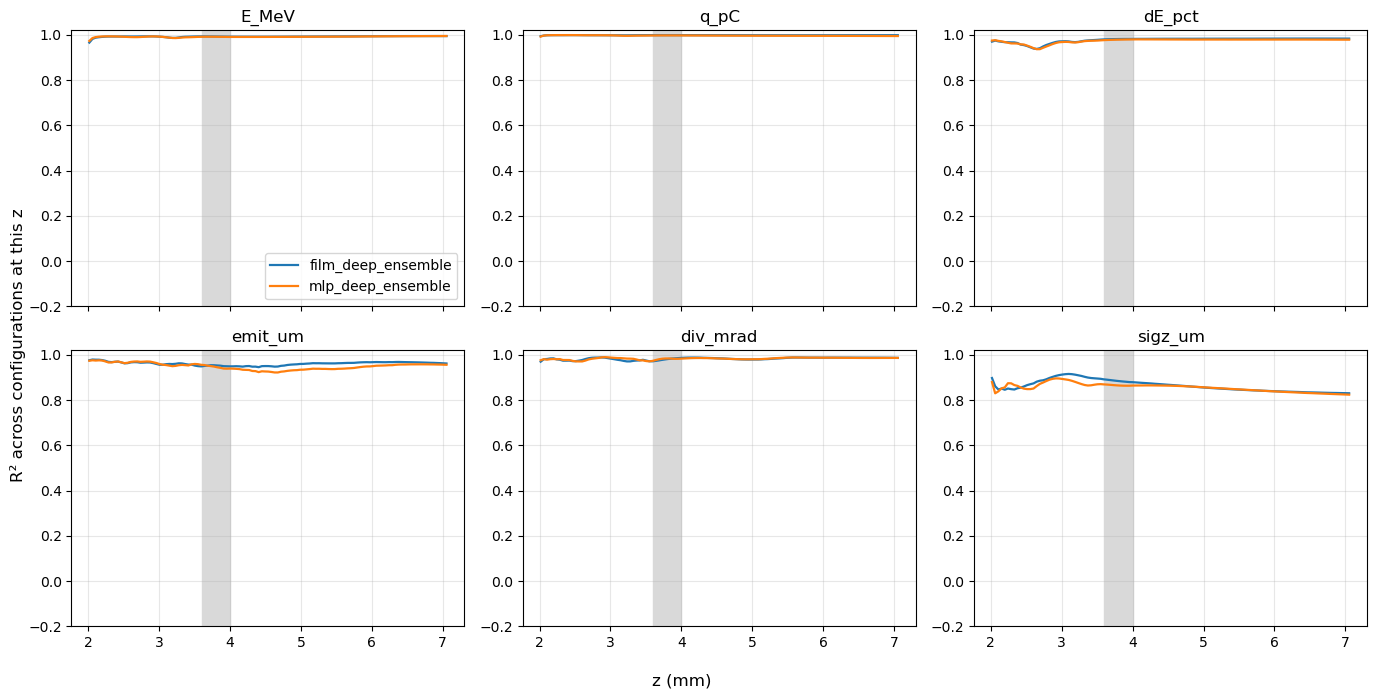

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
for f, r in results.items():
    by_z = pp.r2_by_position(case, r["pred"], key)
    for ax, t in zip(axes.flat, case.targets):
        ax.plot(by_z.z_mm, by_z[t], lw=1.6, label=f)
for ax, t in zip(axes.flat, case.targets):
    ax.axvspan(3.6, 4.0, color="0.85", zorder=0)
    ax.set(title=t, ylim=(-0.2, 1.02))
    ax.grid(alpha=0.3)
axes[0, 0].legend(loc="lower right")
fig.supxlabel("z (mm)")
fig.supylabel("R² across configurations at this z")
fig.tight_layout()

## Register

The fitted ensemble, its model file, `physics_formulas.py` and the holdout scores. With `register = False` the versions already in the registry are used below. Every registered model of the team is in `team_models/<name>_v<version>/`.

In [5]:
versions = {}
for f, r in results.items():
    if register:
        metrics = {"holdout_mean_r2": r["scores"]["mean"],
                   **{f"holdout_r2_{pp.fs_name(t)}": r["scores"][t] for t in case.targets},
                   **{f"holdout_cover2_{pp.fs_name(t)}": c for t, c in zip(case.targets, r["cover"])}}
        info = {"case": "trajectory", "inputs": case.inputs, "targets": case.targets, "feature_columns": list(X_train.columns),
                "feature_view": fv.name, "feature_view_version": fv.version, "td_version": td_version, "model_file": f,
                "params": r["params"], "target_scaling": "scorer", "split": split, "seed": seed,
                "holdout_configs": holdout_configs}
        bundle = pp.save_bundle(r["model"], f"models/{f}.py", info, Path("team_models") / names[f])
        shutil.copy("physics_formulas.py", bundle)
        shown = {k: v for k, v in r["params"].items() if k != "columns"}
        versions[f] = pp.register_model(project, bundle, names[f], fv, td_version, metrics,
                                        f"trajectory: {f} {shown}, {split} holdout (seed {seed})").version
        shutil.rmtree(bundle)
pp.model_benchmark(project, "trajectory").head(15)

,model,version,author,created,mean_r2,from_notebook,E_MeV,q_pC,dE_pct,emit_um,div_mrad,sigz_um,description
0,sj_trajectory_bayesian_nn,5,Sebastien Joly,2026-10-15 12:02:00,0.989398,True,0.997061,0.998019,0.986658,0.985441,0.987457,0.981753,"trajectory: bayesian_nn {'hidden': 512, 'depth..."
1,sj_trajectory_bayesian_nn,4,Sebastien Joly,2026-10-15 08:05:00,0.988546,True,0.996313,0.997363,0.986059,0.984433,0.986449,0.980658,"trajectory: bayesian_nn {'hidden': 256, 'depth..."
2,grl_trajectory_torch_mlp,1,Guillermo Rodriguez Llorente,2026-10-13 15:09:00,0.988404,True,0.996619,0.998149,0.985190,0.984363,0.986393,0.979709,"trajectory: torch_mlp {'hidden': 256, 'depth':..."
3,kkim_trajectory_conventional_mlp,1,Keon Hee Kim,2026-10-15 10:05:00,0.987370,True,0.995432,0.997978,0.983830,0.982413,0.985282,0.979284,"trajectory conventional, random seed=0, local ..."
4,grl_trajectory_mlp_sklearn,1,Guillermo Rodriguez Llorente,2026-10-13 15:09:00,0.987370,True,0.995432,0.997978,0.983830,0.982413,0.985282,0.979284,"trajectory: mlp_sklearn {'hidden': (128, 128, ..."
5,m_trajectory_mlp_deep_ensemble_two_stage,1,mykyta lenivenko,2026-10-14 08:25:00,0.985810,True,0.996579,0.998465,0.981208,0.982247,0.985439,0.970923,"trajectory: mlp_deep_ensemble {'hidden': 64, '..."
6,kkim_trajectory_hybrid_residual_mdn,1,Keon Hee Kim,2026-10-15 10:05:00,0.985666,True,0.994908,0.997323,0.982757,0.980068,0.985496,0.973444,"trajectory bayesian, random seed=0, local hold..."
7,m_trajectory_film_deep_ensemble_two_stage,1,mykyta lenivenko,2026-10-14 08:09:00,0.985073,True,0.996188,0.998705,0.980636,0.981929,0.983212,0.969768,"trajectory: film_deep_ensemble {'hidden': 30, ..."
8,sj_trajectory_bayesian_nn,3,Sebastien Joly,2026-10-15 07:15:00,0.984589,True,0.993720,0.995223,0.981471,0.981116,0.982445,0.973557,"trajectory: bayesian_nn {'hidden': 256, 'depth..."
9,sj_trajectory_bayesian_nn,2,Sebastien Joly,2026-10-13 16:06:00,0.980925,True,0.990639,0.993258,0.977511,0.976907,0.979678,0.967559,"trajectory: bayesian_nn {'hidden': 256, 'depth..."


## Submission, loaded back from the registry

In [6]:
test = pd.read_parquet(pp.DATA_DIR / case.test_file)
for f, name in names.items():
    version = versions.get(f, 1)
    loaded, info = pp.load_registered_model(project, name, version, "team_models")
    X_test = pp.transform(fv, test, case)[info["feature_columns"]]
    path = Path("submissions") / split / f"{name}_v{version}" / pp.submission_file(case, split)
    print("wrote", pp.write_submission(case, pp.predictions(case, loaded, X_test, test), test, path))

Downloading: 0.000%|          | 0/122 elapsed<00:00 remaining<?

Downloading: 100.000%|██████████| 122/122 elapsed<00:00 remaining<00:00

Downloading: 0.000%|          | 0/20393 elapsed<00:00 remaining<?

Downloading: 100.000%|██████████| 20393/20393 elapsed<00:00 remaining<00:00

Downloading: 0.000%|          | 0/27702 elapsed<00:00 remaining<?

...

Downloading: 0.000%|          | 0/242238 elapsed<00:00 remaining<?

Downloading: 100.000%|██████████| 242238/242238 elapsed<00:00 remaining<00:00

Downloading: 0.000%|          | 0/17076 elapsed<00:00 remaining<?

Downloading: 100.000%|██████████| 17076/17076 elapsed<00:00 remaining<00:00

wrote submissions/ood_density/m_trajectory_mlp_deep_ensemble_two_stage_ood_v1/submission_ood.csv
